# Notebook 8 – Distribution Analysis

A distribution describes how frequently different values occur in a feature and how those values are spread across a range

### Normal Distribution


A normal distribution is a continuous, bell-shaped distribution in which values are concentrated around the mean, with fewer observations occurring farther away from the center


Characteristics:

- Bell-shaped curve
- Symmetric around the mean
- Mean, median, and mode are equal in an ideal normal distribution
- Most values are close to the center
- Very high and very low values occur less frequently
- Skewness is approximately zero
- Kurtosis is 3 for the normal distribution when using ordinary Pearson kurtosis, or 0 when using excess kurtosis

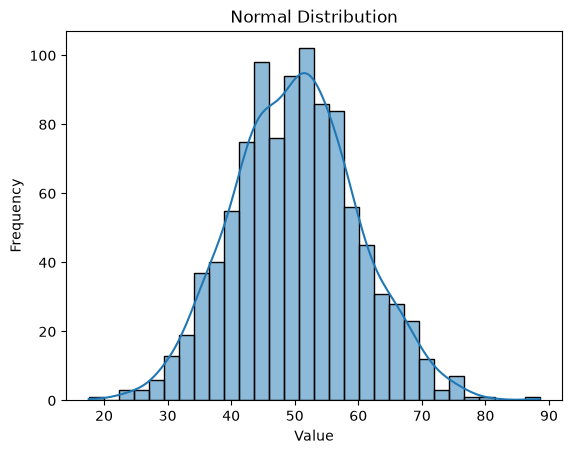

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

data = np.random.normal(loc=50, scale=10, size=1000)

sns.histplot(data, kde=True, bins=30)
plt.title("Normal Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

Here:

- loc=50 sets the population mean to 50
- scale=10 sets the population standard deviation to 10
- size=1000 generates 1,000 observations
- kde=True adds a smooth density curve
- 
Interpretation: If the resulting histogram is approximately symmetric and bell-shaped, the data are consistent with a normal-like distribution. Random samples will not form a perfect bell curve

### Uniform Distribution

A uniform distribution is a distribution in which values within a specified range have equal probability density in the continuous case

Characteristics

- The continuous probability density is flat between its lower and upper limits
- Values are spread relatively evenly across the interval
- There is no single peak within the interval
- For a continuous uniform distribution, the mean and median are both the midpoint of the interval
- The theoretical skewness is zero
- Values outside the specified interval have zero probability

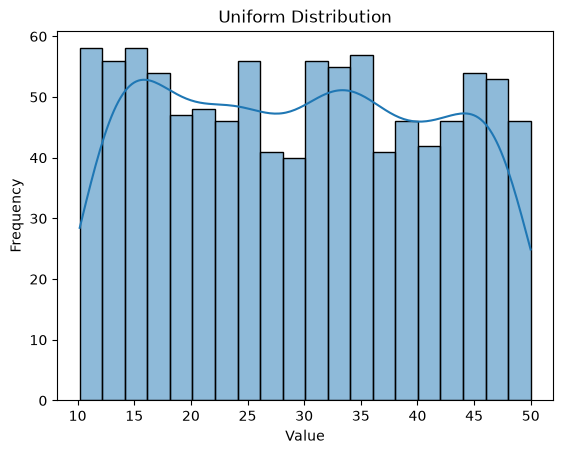

In [2]:
np.random.seed(42)

data = np.random.uniform(low=10, high=50, size=1000)

sns.histplot(data, kde=True, bins=20)
plt.title("Uniform Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

Interpretation: A relatively flat histogram suggests a uniform-like pattern. However, a finite random sample will have fluctuations, so the bars will not be exactly equal.

A uniform distribution is useful as a simulation model or for processes with genuinely equal probability across a range. It should not be assumed for real-world features merely because the histogram looks flat

### Skewness

Skewness measures the asymmetry of a distribution. It tells you whether one side of the distribution has a longer tail than the other

The sign of skewness indicates the direction of the tail

Skewness	      Interpretation	                           Typical shape

Approximately 0	  Little asymmetry	                             Symmetric

Greater than 0	 Tail extends toward larger values          	Right-skewed

Less than 0	     Tail extends toward smaller values	            Left-skewed


### Formula for Skewness

The population moment coefficient of skewness is:

$$
\gamma_1 = \frac{E[(X-\mu)^3]}{\sigma^3}
$$

Where:

- $X$ represents the observations.
- $\mu$ is the population mean.
- $\sigma$ is the population standard deviation.
- $E$ denotes the expected value.


In [5]:
import pandas as pd

data = pd.Series([10, 12, 13, 14, 15, 18, 50])

print("Mean:", data.mean())
print("Median:", data.median())
print("Skewness:", data.skew())

Mean: 18.857142857142858
Median: 14.0
Skewness: 2.472660235912808


The output will show a mean greater than the median and positive skewness, because the unusually large value 50 extends the right tail

Pandas' .skew() calculates a sample skewness statistic with bias correction, so its exact value differs from the population formula above

How to interpret skewness in a real dataset

As a practical starting point, you can use these approximate guidelines:

Absolute skewness	      Possible interpretation

0 to 0.5	              Approximately symmetric or mildly skewed

0.5 to 1	              Moderately skewed

Greater than 1	          Strongly skewed

These are informal guidelines, not universal statistical thresholds. Interpret them alongside the histogram, sample size, and domain context.

### Kurtosis

Kurtosis describes the tail behavior of a distribution, particularly how much probability lies in its tails relative to a normal distribution. It is often used to assess the tendency for extreme observations

A. Mesokurtic distribution

- Has the same kurtosis as a normal distribution under the usual Pearson definition.
- Pearson kurtosis equals 3.
- Excess kurtosis equals 0
  
B. Leptokurtic distribution

- Has positive excess kurtosis
- Has heavier tails than the normal reference distribution, in the moment-based sense
- May be more prone to extreme observations
  
C. Platykurtic distribution

- Has negative excess kurtosis
- Has lighter tails than the normal reference distribution, in the moment-based sense
- A uniform distribution is a standard example


Formula for Kurtosis

Pearson kurtosis is defined as:

$$
\beta_2 = \frac{E[(X-\mu)^4]}{\sigma^4}
$$

Excess kurtosis is:

$$
\text{Excess Kurtosis} = \beta_2 - 3
$$

Subtracting 3 makes the excess kurtosis of a normal distribution equal to zero


In [6]:
data = pd.Series([10, 12, 13, 14, 15, 18, 50])

print("Kurtosis:", data.kurt())

Kurtosis: 6.293894217000776


Pandas .kurt() returns sample excess kurtosis, not Pearson kurtosis

How to interpret it:

- Positive excess kurtosis: heavier tails relative to the normal reference, as measured by kurtosis.
- Approximately zero: kurtosis similar to the normal reference.
- Negative excess kurtosis: lighter tails relative to the normal referece

Kurtosis alone does not tell you whether a distribution is symmetric or skewed. A distribution can have positive excess kurtosis and still be symmetric, or it can be skewed.

### Symmetric Distribution

A symmetric distribution has approximately the same shape on both sides of its center

Characteristics
- The left and right sides are mirror images in a perfectly symmetric distribution.
- The mean and median coincide when the distribution is symmetric and the mean exists.
- Skewness is zero when the third central moment exists.
- The distribution may be bell-shaped, flat-topped, or have another symmetric shape.
Important distinction: Every normal distribution is symmetric, but not every symmetric distribution is normal.

For example, a symmetric distribution may have heavy tails or multiple peaks. Therefore, zero skewness does not prove normality.

### Right-Skewed Distribution (Positive Skewness)

A right-skewed distribution has a long tail extending toward larger values

Characteristics

- Most observations are concentrated at relatively low or moderate values.
- A small number of observations extend toward much higher values.
- Skewness is positive.
- The mean is often greater than the median.
- High-value outliers may be present

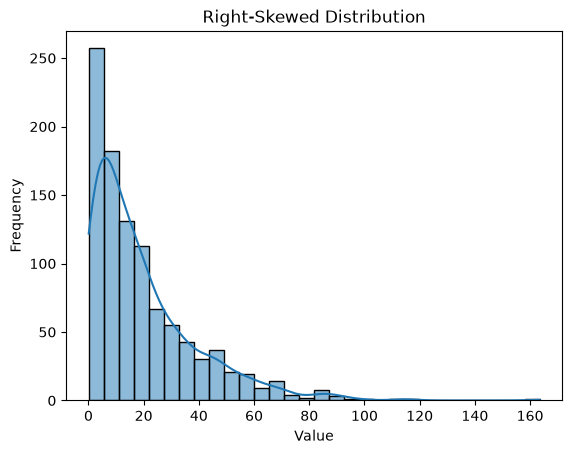

In [3]:
np.random.seed(42)

data = np.random.exponential(scale=20, size=1000)

sns.histplot(data, kde=True, bins=30)
plt.title("Right-Skewed Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

Interpretation: If most observations are small and a long tail extends toward large values, the distribution is right-skewed. The mean may be pulled upward by a few large observations

Common examples include income, transaction amounts, customer spending, and some business revenue measures

### Left-Skewed Distribution (Negative Skewness)

A left-skewed distribution has a long tail extending toward smaller values

Characteristics

- Most observations are concentrated toward higher values
- A smaller number of low values form a long left tail
- Skewness is negative
- The mean is often less than the median
- Low-value outliers may be present

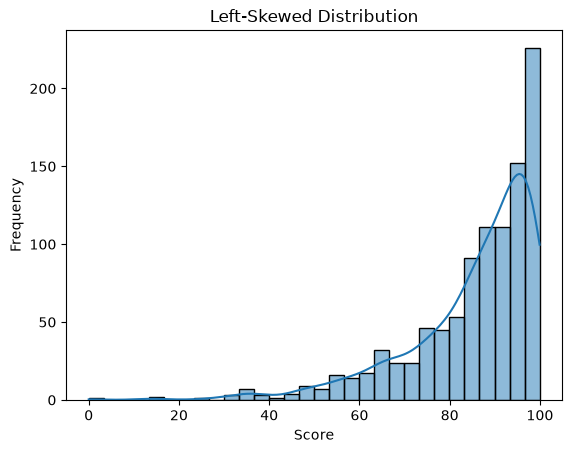

In [4]:
np.random.seed(42)

data = 100 - np.random.exponential(scale=15, size=1000)
data = np.clip(data, 0, 100)

sns.histplot(data, kde=True, bins=30)
plt.title("Left-Skewed Distribution")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.show()

In [9]:
import pandas as pd                              #ExampleDataset
    "mean",
    "median",
    "std",
    "min",
    "max",
    "skew",
    "kurt"
]).T

summary["IQR"] = (
    df[numerical_cols].quantile(0.75)
    - df[numerical_cols].quantile(0.25)
)

summary.round(2)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Study_Hours": [1, 2, 2, 3, 3, 4, 4, 5, 5, 6,
                    6, 7, 7, 8, 9, 10, 12, 14, 15, 20],

    "Exam_Score": [45, 50, 52, 55, 58, 60, 62, 65, 66, 68,
                   70, 72, 74, 75, 78, 80, 82, 85, 88, 98],

    "Attendance_Percentage": [55, 60, 65, 70, 75, 78, 80, 82,
                              85, 86, 88, 90, 91, 92, 93, 94,
                              95, 96, 98, 100],

    "Assignment_Score": [40, 45, 50, 55, 60, 65, 68, 70, 72, 75,
                         78, 80, 82, 85, 88, 90, 92, 95, 98, 100]
})

df.head()

,Study_Hours,Exam_Score,Attendance_Percentage,Assignment_Score
0,1,45,55,40
1,2,50,60,45
2,2,52,65,50
3,3,55,70,55
4,3,58,75,60


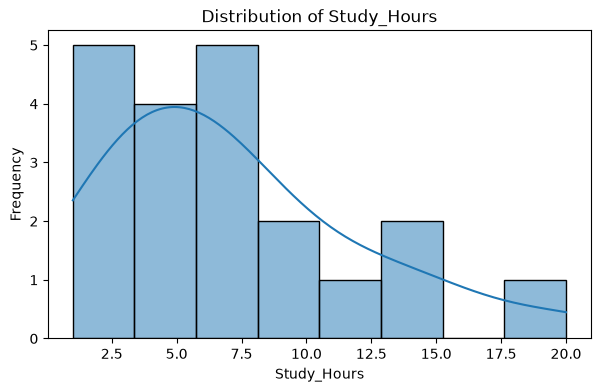

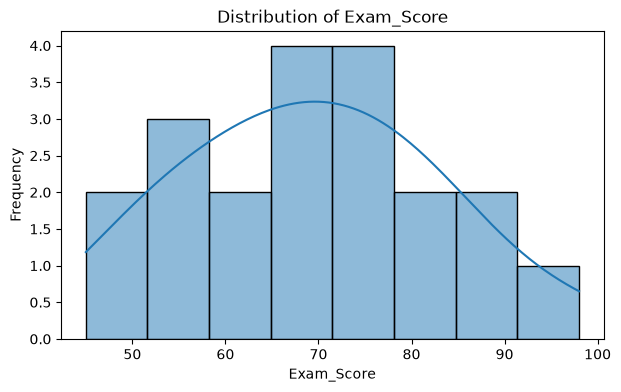

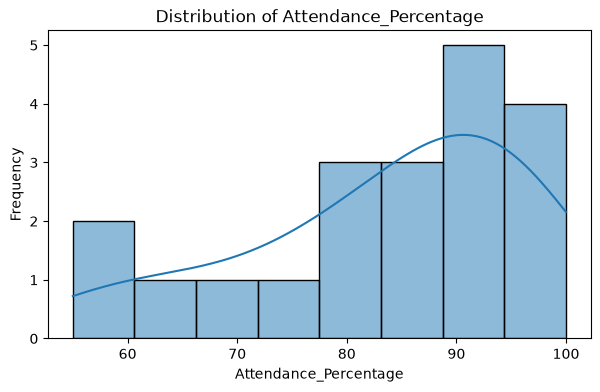

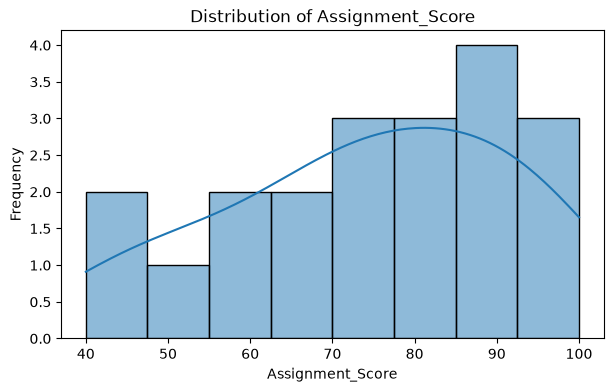

In [10]:
numerical_cols = df.select_dtypes(include="number").columns              #Analyze the shape of the distribution

for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], bins=8, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

What to observe:

- Study_Hours: Most students study for fewer hours, with a tail extending toward higher hours.
- Exam_Score: Scores are concentrated around the middle-to-high range, with a few higher scores.
- Attendance_Percentage: Values are concentrated toward higher attendance levels.
- Assignment_Score: Scores cover a broad range, with several high values.

In [11]:
for col in numerical_cols:                           #Analyze the center
    print(f"\n{col}")
    print("Mean:", round(df[col].mean(), 2))
    print("Median:", round(df[col].median(), 2))
    print("Mode:", df[col].mode().tolist())


Study_Hours
Mean: 7.15
Median: 6.0
Mode: [2, 3, 4, 5, 6, 7]

Exam_Score
Mean: 69.15
Median: 69.0
Mode: [45, 50, 52, 55, 58, 60, 62, 65, 66, 68, 70, 72, 74, 75, 78, 80, 82, 85, 88, 98]

Attendance_Percentage
Mean: 83.65
Median: 87.0
Mode: [55, 60, 65, 70, 75, 78, 80, 82, 85, 86, 88, 90, 91, 92, 93, 94, 95, 96, 98, 100]

Assignment_Score
Mean: 74.4
Median: 76.5
Mode: [40, 45, 50, 55, 60, 65, 68, 70, 72, 75, 78, 80, 82, 85, 88, 90, 92, 95, 98, 100]


observations:

- If mean and median are close, the feature may be approximately symmetric.
- If mean is greater than median, the feature may be right-skewed.
- If mean is less than median, the feature may be left-skewed.

In [12]:
for col in numerical_cols:                          #Analyze the spread
    x = df[col]

    print(f"\n{col}")
    print("Range:", x.max() - x.min())
    print("Variance:", round(x.var(), 2))
    print("Standard Deviation:", round(x.std(), 2))
    print("IQR:", x.quantile(0.75) - x.quantile(0.25))


Study_Hours
Range: 19
Variance: 24.56
Standard Deviation: 4.96
IQR: 5.5

Exam_Score
Range: 53
Variance: 189.4
Standard Deviation: 13.76
IQR: 19.0

Attendance_Percentage
Range: 45
Variance: 167.19
Standard Deviation: 12.93
IQR: 16.0

Assignment_Score
Range: 60
Variance: 314.25
Standard Deviation: 17.73
IQR: 24.75


Interpretation:

- A larger range means the minimum and maximum are farther apart
- A larger standard deviation indicates greater variation around the mean
- A larger IQR indicates greater variation among the middle 50% of students
- 
Because these features use different scales, compare their relative variability carefully.

In [13]:
for col in numerical_cols:                      #Analyze skewness and kurtosis
    print(f"\n{col}")
    print("Skewness:", round(df[col].skew(), 3))
    print("Excess Kurtosis:", round(df[col].kurt(), 3))


Study_Hours
Skewness: 1.123
Excess Kurtosis: 0.962

Exam_Score
Skewness: 0.169
Excess Kurtosis: -0.402

Attendance_Percentage
Skewness: -0.885
Excess Kurtosis: -0.097

Assignment_Score
Skewness: -0.418
Excess Kurtosis: -0.743


Interpretation:

- Positive skewness: Longer tail toward higher values
- Negative skewness: Longer tail toward lower values
- Skewness near zero: Little measured asymmetry
- Positive excess kurtosis: Greater tail weight relative to a normal reference, according to the kurtosis measure
- Negative excess kurtosis: Lower tail weight relative to a normal reference

In [14]:
Detect potential outliersfor col in numerical_cols:                  #Potential outliers
    x = df[col]

    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = x[
        (x < lower_bound) | (x > upper_bound)
    ]

    print(f"\n{col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", outliers.tolist())


Study_Hours
Lower Bound: -4.5
Upper Bound: 17.5
Potential Outliers: [20]

Exam_Score
Lower Bound: 31.0
Upper Bound: 107.0
Potential Outliers: []

Attendance_Percentage
Lower Bound: 53.25
Upper Bound: 117.25
Potential Outliers: []

Assignment_Score
Lower Bound: 26.625
Upper Bound: 125.625
Potential Outliers: []


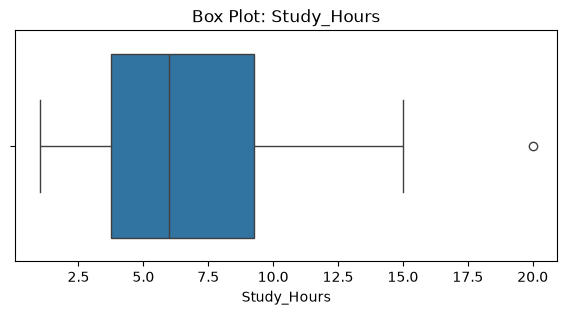

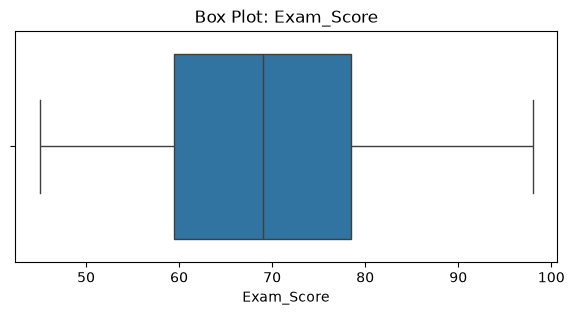

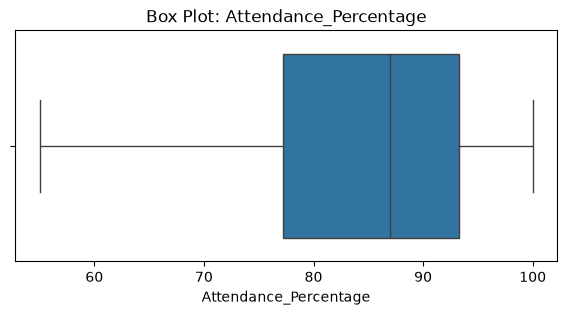

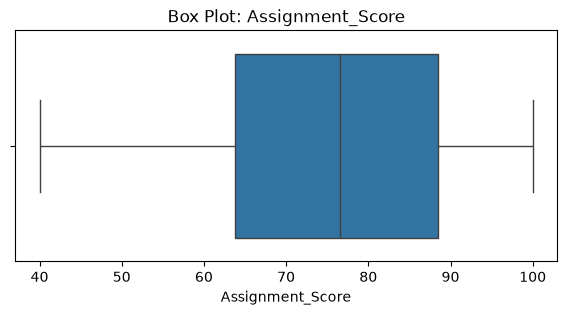

In [16]:
for col in numerical_cols:                  #Visualize
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot: {col}")
    plt.show()

In [15]:
summary = df[numerical_cols].agg([                  #final distribution summary
    "mean",
    "median",
    "std",
    "min",
    "max",
    "skew",
    "kurt"
]).T

summary["IQR"] = (
    df[numerical_cols].quantile(0.75)
    - df[numerical_cols].quantile(0.25)
)

summary.round(2)

,mean,median,std,min,max,skew,kurt,IQR
Study_Hours,7.15,6.0,4.96,1.0,20.0,1.12,0.96,5.50
Exam_Score,69.15,69.0,13.76,45.0,98.0,0.17,-0.40,19.00
Attendance_Percentage,83.65,87.0,12.93,55.0,100.0,-0.89,-0.10,16.00
Assignment_Score,74.40,76.5,17.73,40.0,100.0,-0.42,-0.74,24.75


Study_Hours

- Shape: Examine whether the distribution is symmetric or right-skewed
- Center: Compare the mean and median to understand typical study hours
- Spread: Use the standard deviation and IQR to describe differences between students
- Skewness: Use the skewness value and histogram to determine the direction of asymmetry
- Outliers: Check whether unusually high study hours are flagged by the IQR method